# Exploratory Data Analysis — Ames Housing

## Part A: Dataset Understanding & Data Quality

This section examines the structure, variable types,descriptive statistics, missing values, and potential outliers in the Ames Housing dataset.

In [3]:

# A1 - read dataset

from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Path relative to the notebook directory
DATA_PATH = Path("data/AmesHousing.csv")

# The provided dataset is tab-separated
df = pd.read_csv(DATA_PATH, sep="\t")

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (2930, 82)


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


# Dataset dimensions

In [4]:

# A2 - dataset overview

n_rows, n_columns = df.shape

print(f"Number of observations: {n_rows}")
print(f"Number of features/columns: {n_columns}")
print(f"Total number of cells: {df.size}")


Number of observations: 2930
Number of features/columns: 82
Total number of cells: 240260


# Statistical Feature Classification

In [6]:
# A3 - statistical feature classification, identifier columns, target variable

# A3.1 - feature types
feature_types = {
    "Nominal": [
        "MS SubClass", "MS Zoning", "Street", "Alley",
        "Land Contour", "Lot Config", "Neighborhood",
        "Condition 1", "Condition 2", "Bldg Type",
        "House Style", "Roof Style", "Roof Matl",
        "Exterior 1st", "Exterior 2nd", "Mas Vnr Type",
        "Foundation", "Heating", "Central Air",
        "Garage Type", "Misc Feature",
        "Sale Type", "Sale Condition"
    ],
    "Ordinal": [
        "Lot Shape", "Utilities", "Land Slope",
        "Overall Qual", "Overall Cond",
        "Exter Qual", "Exter Cond",
        "Bsmt Qual", "Bsmt Cond", "Bsmt Exposure",
        "BsmtFin Type 1", "BsmtFin Type 2",
        "Heating QC", "Electrical", "Kitchen Qual",
        "Functional", "Fireplace Qu",
        "Garage Finish", "Garage Qual", "Garage Cond",
        "Paved Drive", "Pool QC", "Fence"
    ],
    "Discrete": [
        "Year Built", "Year Remod/Add",
        "Bsmt Full Bath", "Bsmt Half Bath",
        "Full Bath", "Half Bath", "Bedroom AbvGr",
        "Kitchen AbvGr", "TotRms AbvGrd",
        "Fireplaces", "Garage Yr Blt", "Garage Cars",
        "Mo Sold", "Yr Sold"
    ],
    "Continuous": [
        "Lot Frontage", "Lot Area", "Mas Vnr Area",
        "BsmtFin SF 1", "BsmtFin SF 2",
        "Bsmt Unf SF", "Total Bsmt SF",
        "1st Flr SF", "2nd Flr SF", "Low Qual Fin SF",
        "Gr Liv Area", "Garage Area",
        "Wood Deck SF", "Open Porch SF",
        "Enclosed Porch", "3Ssn Porch",
        "Screen Porch", "Pool Area", "Misc Val"
    ]
}

identifier_columns = ["Order", "PID"]
target_column = "SalePrice"


In [7]:

# A3.2 - validation

from collections import Counter

classified_columns = [
    col
    for columns in feature_types.values()
    for col in columns
]

all_assigned = (
    classified_columns
    + identifier_columns
    + [target_column]
)

missing_from_classification = sorted(
    set(df.columns) - set(all_assigned)
)

unknown_columns = sorted(
    set(all_assigned) - set(df.columns)
)

duplicates = [
    col for col, count in Counter(all_assigned).items()
    if count > 1
]

print("Feature counts by statistical type:")
for feature_type, columns in feature_types.items():
    print(f"{feature_type}: {len(columns)}")

print("\nUnclassified columns:", missing_from_classification)
print("Unknown column names:", unknown_columns)
print("Duplicate assignments:", duplicates)

assert not missing_from_classification
assert not unknown_columns
assert not duplicates

print("\nAll dataset columns classified successfully!")

Feature counts by statistical type:
Nominal: 23
Ordinal: 23
Discrete: 14
Continuous: 19

Unclassified columns: []
Unknown column names: []
Duplicate assignments: []

All dataset columns classified successfully!


In [11]:

# A3.3 - data display

classification_table = pd.DataFrame(
    [
        {"Feature": column, "Statistical Type": feature_type}
        for feature_type, columns in feature_types.items()
        for column in columns
    ]
)

classification_table = classification_table.sort_values(
    ["Statistical Type", "Feature"]
).reset_index(drop=True)


for feature_type in feature_types:
    print(f"\n--- {feature_type.upper()} ---")

    display(
        classification_table[
            classification_table["Statistical Type"] == feature_type
        ]
    )




--- NOMINAL ---


,Feature,Statistical Type
33,Alley,Nominal
34,Bldg Type,Nominal
35,Central Air,Nominal
36,Condition 1,Nominal
37,Condition 2,Nominal
38,Exterior 1st,Nominal
39,Exterior 2nd,Nominal
40,Foundation,Nominal
41,Garage Type,Nominal
42,Heating,Nominal



--- ORDINAL ---


,Feature,Statistical Type
56,Bsmt Cond,Ordinal
57,Bsmt Exposure,Ordinal
58,Bsmt Qual,Ordinal
59,BsmtFin Type 1,Ordinal
60,BsmtFin Type 2,Ordinal
61,Electrical,Ordinal
62,Exter Cond,Ordinal
63,Exter Qual,Ordinal
64,Fence,Ordinal
65,Fireplace Qu,Ordinal



--- DISCRETE ---


,Feature,Statistical Type
19,Bedroom AbvGr,Discrete
20,Bsmt Full Bath,Discrete
21,Bsmt Half Bath,Discrete
22,Fireplaces,Discrete
23,Full Bath,Discrete
24,Garage Cars,Discrete
25,Garage Yr Blt,Discrete
26,Half Bath,Discrete
27,Kitchen AbvGr,Discrete
28,Mo Sold,Discrete



--- CONTINUOUS ---


,Feature,Statistical Type
0,1st Flr SF,Continuous
1,2nd Flr SF,Continuous
2,3Ssn Porch,Continuous
3,Bsmt Unf SF,Continuous
4,BsmtFin SF 1,Continuous
5,BsmtFin SF 2,Continuous
6,Enclosed Porch,Continuous
7,Garage Area,Continuous
8,Gr Liv Area,Continuous
9,Lot Area,Continuous


### Interpretation

The Ames Housing dataset contains four main statistical feature types: nominal, ordinal, discrete, and continuous.

- Nominal variables describe unordered categories, such as neighborhood and building type.
- Ordinal variables represent ordered evaluations, such as overall quality and exterior condition.
- Discrete variables include counts of rooms and bathrooms, as well as recorded years and months.
- Continuous variables describe measurable properties, such as living area and lot size.

The classification is based on the dataset's data dictionary.
Identifier columns (`Order` and `PID`) are treated separately,
while `SalePrice` is identified as the target variable.

## Descriptive Statistics

This section summarizes the statistical properties of the Ames Housing dataset according to the semantic feature types.

Different descriptive measures are used for nominal, ordinal, discrete, and continuous features.

In [12]:

# A4.1 — Nominal features

nominal_summary = pd.DataFrame([
    {
        "Feature": col,
        "Unique Categories": df[col].nunique(dropna=True),
        "Most Frequent Category": (
            df[col].mode(dropna=True).iloc[0]
            if df[col].notna().any() else np.nan
        ),
        "Mode Frequency": (
            df[col].value_counts().iloc[0]
            if df[col].notna().any() else 0
        ),
        "Mode Percentage": (
            df[col].value_counts(normalize=True).iloc[0] * 100
            if df[col].notna().any() else np.nan
        )
    }
    for col in feature_types["Nominal"]
])

display(nominal_summary.round(2))

,Feature,Unique Categories,Most Frequent Category,Mode Frequency,Mode Percentage
0,MS SubClass,16,20,1079,36.83
1,MS Zoning,7,RL,2273,77.58
2,Street,2,Pave,2918,99.59
3,Alley,2,Grvl,120,60.61
4,Land Contour,4,Lvl,2633,89.86
5,Lot Config,5,Inside,2140,73.04
6,Neighborhood,28,NAmes,443,15.12
7,Condition 1,9,Norm,2522,86.08
8,Condition 2,8,Norm,2900,98.98
9,Bldg Type,5,1Fam,2425,82.76


### Interpretation — Nominal Features

The dataset contains 23 nominal features describing property characteristics such as zoning, neighborhood, building type, and construction materials.

Several categories strongly dominate their respective features. For example, 82.76% of properties are single-family detached houses, 77.58% are located in low-density residential zones, and 93.31% have central air conditioning.

The dataset includes 28 neighborhoods, but their representation is uneven. North Ames accounts for 15.12% of all observations, while some neighborhoods contain only one or two properties. This imbalance should be considered when comparing property prices across neighborhoods.

Certain nominal features, particularly `Alley` and `Misc Feature`, require special attention because missing entries may indicate the absence of a physical feature rather than unknown information. Therefore, category percentages calculated over non-missing observations must be interpreted carefully.

In [13]:

# Neighborhood distribution

neighborhood_distribution = pd.DataFrame({
    "Count": df["Neighborhood"].value_counts(),
    "Percentage": (
        df["Neighborhood"].value_counts(normalize=True) * 100
    ).round(2)
})

display(neighborhood_distribution)


,Count,Percentage
Neighborhood,,
NAmes,443,15.12
CollgCr,267,9.11
OldTown,239,8.16
Edwards,194,6.62
Somerst,182,6.21
NridgHt,166,5.67
Gilbert,165,5.63
Sawyer,151,5.15
NWAmes,131,4.47


Overall Qual
1       4
2      13
3      40
4     226
5     825
6     732
7     602
8     350
9     107
10     31
Name: count, dtype: int64

Median overall quality: 6.0
Most frequent quality rating: 5


,Quality Score,Description,Count,Percentage
0,1,Very Poor,4,0.14
1,2,Poor,13,0.44
2,3,Fair,40,1.37
3,4,Below Average,226,7.71
4,5,Average,825,28.16
5,6,Above Average,732,24.98
6,7,Good,602,20.55
7,8,Very Good,350,11.95
8,9,Excellent,107,3.65
9,10,Very Excellent,31,1.06


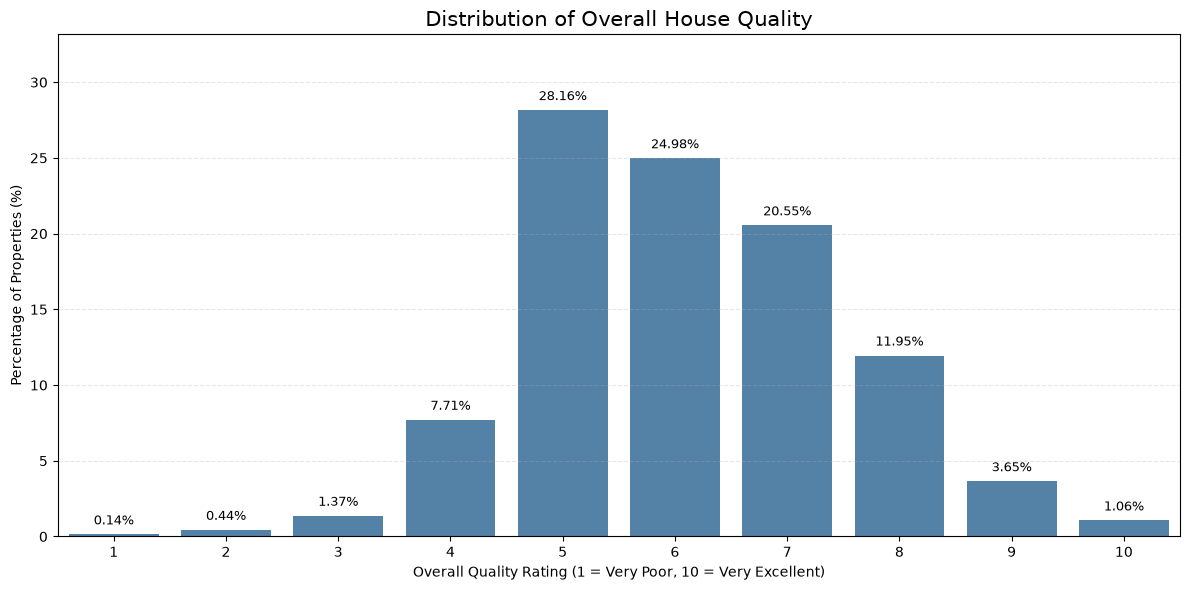

In [20]:

# A4.2 — Ordinal features
# Frequency distribution of overall quality

overall_quality_distribution = (
    df["Overall Qual"]
    .value_counts(dropna=False)
    .sort_index()
)

display(overall_quality_distribution)

print(
    "Median overall quality:",
    df["Overall Qual"].median()
)

print(
    "Most frequent quality rating:",
    df["Overall Qual"].mode().iloc[0]
)


quality_labels = {
    1: "Very Poor",
    2: "Poor",
    3: "Fair",
    4: "Below Average",
    5: "Average",
    6: "Above Average",
    7: "Good",
    8: "Very Good",
    9: "Excellent",
    10: "Very Excellent"
}

quality_distribution = (
    df["Overall Qual"]
    .value_counts()
    .sort_index()
    .rename_axis("Quality Score")
    .reset_index(name="Count")
)

quality_distribution["Description"] = (
    quality_distribution["Quality Score"].map(quality_labels)
)

quality_distribution["Percentage"] = (
    quality_distribution["Count"] / len(df) * 100
).round(2)

display(
    quality_distribution[
        ["Quality Score", "Description", "Count", "Percentage"]
    ]
)


# A4.2 — Overall Quality Distribution

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=quality_distribution,
    x="Quality Score",
    y="Percentage",
    color="steelblue"
)

# Display percentages above each bar
for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f"{height:.2f}%",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom",
        xytext=(0, 5),
        textcoords="offset points",
        fontsize=9
    )

plt.title("Distribution of Overall House Quality", fontsize=15)
plt.xlabel("Overall Quality Rating (1 = Very Poor, 10 = Very Excellent)")
plt.ylabel("Percentage of Properties (%)")

plt.ylim(0, quality_distribution["Percentage"].max() + 5)
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()


### Interpretation — Overall Quality

The `Overall Qual` feature is ordinal, representing the overall quality of materials and finishes on a scale from 1 (Very Poor) to 10 (Very Excellent).

The most frequent quality rating is 5 (Average), representing 28.16% of the properties, while the median rating is 6 (Above Average).

Approximately 73.69% of properties have quality ratings between 5 and 7, indicating that the dataset is predominantly composed of houses with average to good overall quality.

Only 9.66% of properties have ratings below 5, while 16.66% have ratings of 8 or higher. Thus, very low and very high quality ratings are comparatively uncommon.

These findings describe the distribution of housing quality but do not yet establish its relationship with sale price.

In [21]:

# A4.4 — Continuous features

continuous_summary = df[
    feature_types["Continuous"]
].describe().T

display(continuous_summary.round(2))


# A4.4 — Skewness of continuous features

continuous_skewness = (
    df[feature_types["Continuous"]]
    .skew()
    .sort_values(ascending=False)
    .to_frame(name="Skewness")
)

display(continuous_skewness.round(3))


,count,mean,std,min,25%,50%,75%,max
Lot Frontage,2440.0,69.22,23.37,21.0,58.00,68.0,80.00,313.0
Lot Area,2930.0,10147.92,7880.02,1300.0,7440.25,9436.5,11555.25,215245.0
Mas Vnr Area,2907.0,101.90,179.11,0.0,0.00,0.0,164.00,1600.0
BsmtFin SF 1,2929.0,442.63,455.59,0.0,0.00,370.0,734.00,5644.0
BsmtFin SF 2,2929.0,49.72,169.17,0.0,0.00,0.0,0.00,1526.0
Bsmt Unf SF,2929.0,559.26,439.49,0.0,219.00,466.0,802.00,2336.0
Total Bsmt SF,2929.0,1051.61,440.62,0.0,793.00,990.0,1302.00,6110.0
1st Flr SF,2930.0,1159.56,391.89,334.0,876.25,1084.0,1384.00,5095.0
2nd Flr SF,2930.0,335.46,428.40,0.0,0.00,0.0,703.75,2065.0
Low Qual Fin SF,2930.0,4.68,46.31,0.0,0.00,0.0,0.00,1064.0


,Skewness
Misc Val,22.000
Pool Area,16.939
Lot Area,12.821
Low Qual Fin SF,12.118
3Ssn Porch,11.404
BsmtFin SF 2,4.140
Enclosed Porch,4.014
Screen Porch,3.957
Mas Vnr Area,2.607
Open Porch SF,2.535


### Interpretation — Continuous Features

The descriptive statistics reveal substantial variability in the physical dimensions of properties in the Ames Housing dataset.

The average lot area is approximately 10,148 square feet, compared with a median of 9,436.5 square feet. The maximum lot area reaches 215,245 square feet, suggesting a potentially right-skewed distribution with unusually large properties.

A similar pattern can be observed for above-ground living area (`Gr Liv Area`) and total basement area (`Total Bsmt SF`), where maximum values considerably exceed their respective medians.

Several features, including `Pool Area`, `3Ssn Porch`, `Low Qual Fin SF`, and `Misc Val`, have both a median and a 75th percentile equal to zero. This indicates that these characteristics are absent or have no recorded area or value for at least 75% of the properties.

The analysis also identifies incomplete observations. In particular, `Lot Frontage` contains 490 missing values, representing approximately 16.72% of the dataset.

Overall, the continuous features exhibit considerable variation, potentially asymmetric distributions, and some unusually large observations. These findings motivate further investigation of missing values and outliers in the following sections.

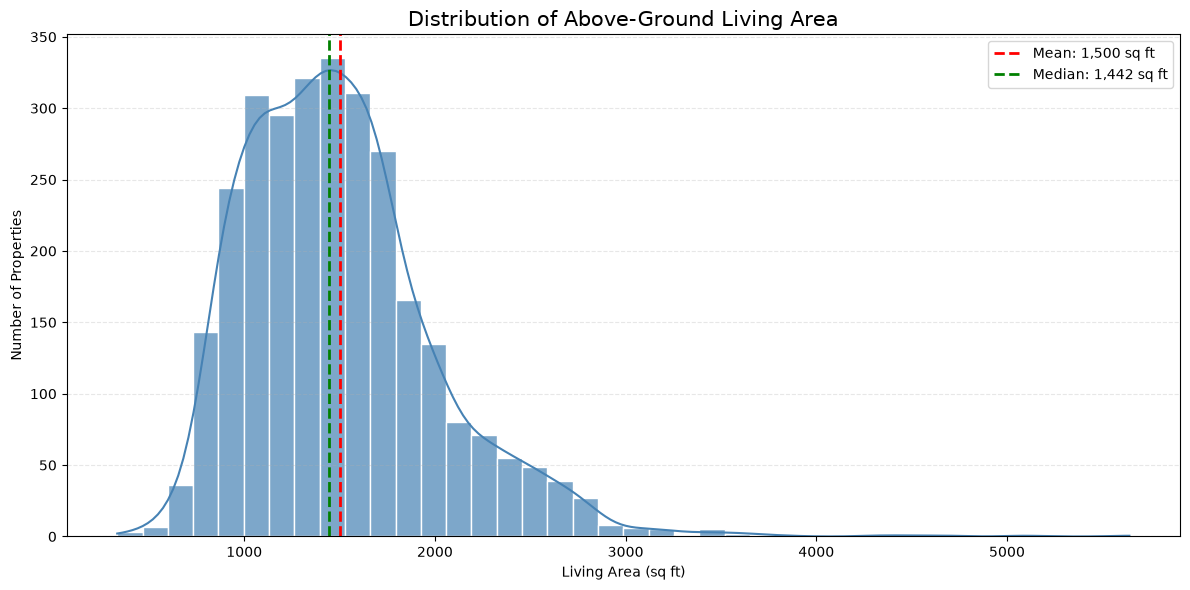

In [22]:

# A4.4 — Distribution of Above-Ground Living Area

plt.figure(figsize=(12, 6))

sns.histplot(
    data=df,
    x="Gr Liv Area",
    bins=40,
    kde=True,
    color="steelblue",
    edgecolor="white",
    alpha=0.7
)

# Mean and median reference lines
mean_area = df["Gr Liv Area"].mean()
median_area = df["Gr Liv Area"].median()

plt.axvline(
    mean_area,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Mean: {mean_area:,.0f} sq ft"
)

plt.axvline(
    median_area,
    color="green",
    linestyle="--",
    linewidth=2,
    label=f"Median: {median_area:,.0f} sq ft"
)

plt.title("Distribution of Above-Ground Living Area", fontsize=15)
plt.xlabel("Living Area (sq ft)")
plt.ylabel("Number of Properties")

plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()


### Interpretation — Above-Ground Living Area Distribution

The histogram illustrates the distribution of above-ground living area (`Gr Liv Area`) across the 2,930 properties in the dataset.

The mean living area is approximately 1,500 square feet, while the median is 1,442 square feet. The mean being higher than the median suggests a positively skewed distribution.

Most properties are expected to be concentrated around moderate living areas, while a smaller number of houses have substantially larger living spaces. The maximum recorded living area is 5,642 square feet.

The unusually large observations warrant further investigation during the outlier analysis. However, they should not automatically be considered errors or removed from the dataset.

count      2930.00
mean     180796.06
std       79886.69
min       12789.00
25%      129500.00
50%      160000.00
75%      213500.00
max      755000.00
Name: SalePrice, dtype: float64

SalePrice skewness: 1.744


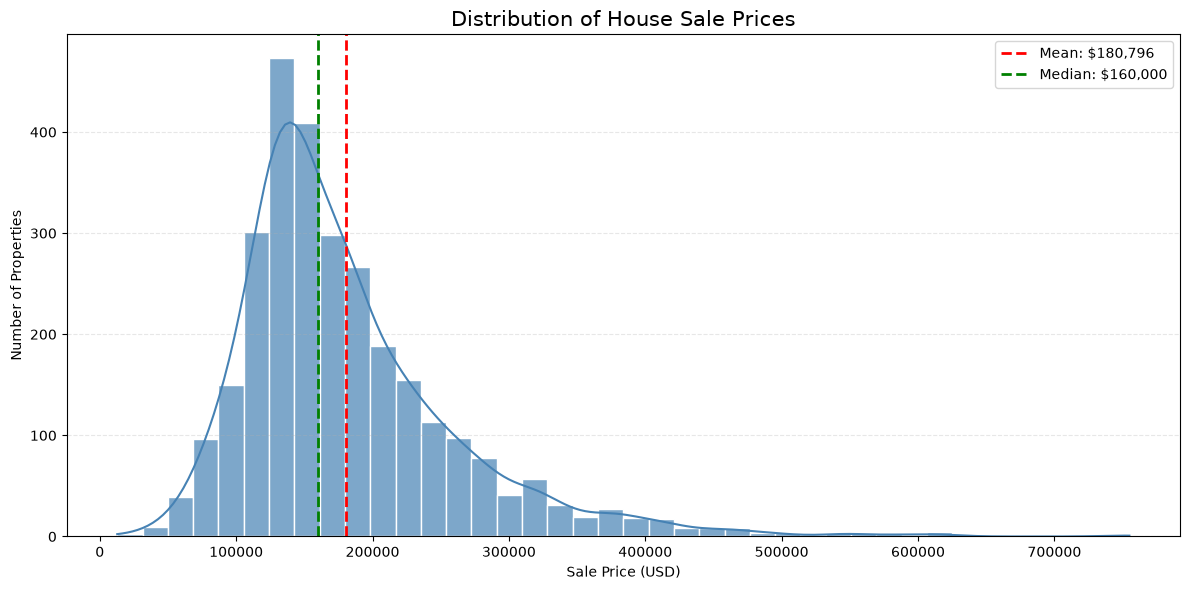

In [23]:

# A4.5 — Target variable

sale_price_summary = df["SalePrice"].describe()

display(sale_price_summary.round(2))

print(
    "SalePrice skewness:",
    round(df["SalePrice"].skew(), 3)
)


# A4.5 — SalePrice Distribution

plt.figure(figsize=(12, 6))

sns.histplot(
    data=df,
    x="SalePrice",
    bins=40,
    kde=True,
    color="steelblue",
    edgecolor="white",
    alpha=0.7
)

# Mean and median reference lines
mean_price = df["SalePrice"].mean()
median_price = df["SalePrice"].median()

plt.axvline(
    mean_price,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Mean: ${mean_price:,.0f}"
)

plt.axvline(
    median_price,
    color="green",
    linestyle="--",
    linewidth=2,
    label=f"Median: ${median_price:,.0f}"
)

plt.title("Distribution of House Sale Prices", fontsize=15)
plt.xlabel("Sale Price (USD)")
plt.ylabel("Number of Properties")

plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()


### Interpretation — SalePrice Distribution

The distribution of `SalePrice`, the target variable, exhibits substantial positive skewness, with a skewness coefficient of 1.744.

This indicates that house sale prices are not symmetrically distributed. Most properties are concentrated in the lower and middle price ranges, while a relatively small number of expensive properties extend the distribution toward higher values.

The high-priced observations influence the mean more strongly than the median, making the median a useful measure of the typical sale price.

The right-skewed distribution also suggests that unusually expensive properties should be investigated during the outlier analysis. However, high prices do not necessarily represent errors, and these observations should not be removed without further justification.

For future predictive modeling, a logarithmic transformation of `SalePrice` could be investigated to reduce skewness, but no transformation is applied at this exploratory stage.

In [24]:

# A5.1 — Missing Values Overview

missing_summary = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": df.isna().mean() * 100
})

missing_summary = (
    missing_summary[missing_summary["Missing Count"] > 0]
    .sort_values("Missing Count", ascending=False)
)

print(f"Total observations: {len(df)}")
print(f"Total features with missing values: {len(missing_summary)}")
print(f"Total missing cells: {df.isna().sum().sum()}")

display(missing_summary.round(2))


Total observations: 2930
Total features with missing values: 27
Total missing cells: 15749


,Missing Count,Missing Percentage
Pool QC,2917,99.56
Misc Feature,2824,96.38
Alley,2732,93.24
Fence,2358,80.48
Mas Vnr Type,1775,60.58
Fireplace Qu,1422,48.53
Lot Frontage,490,16.72
Garage Qual,159,5.43
Garage Cond,159,5.43
Garage Yr Blt,159,5.43


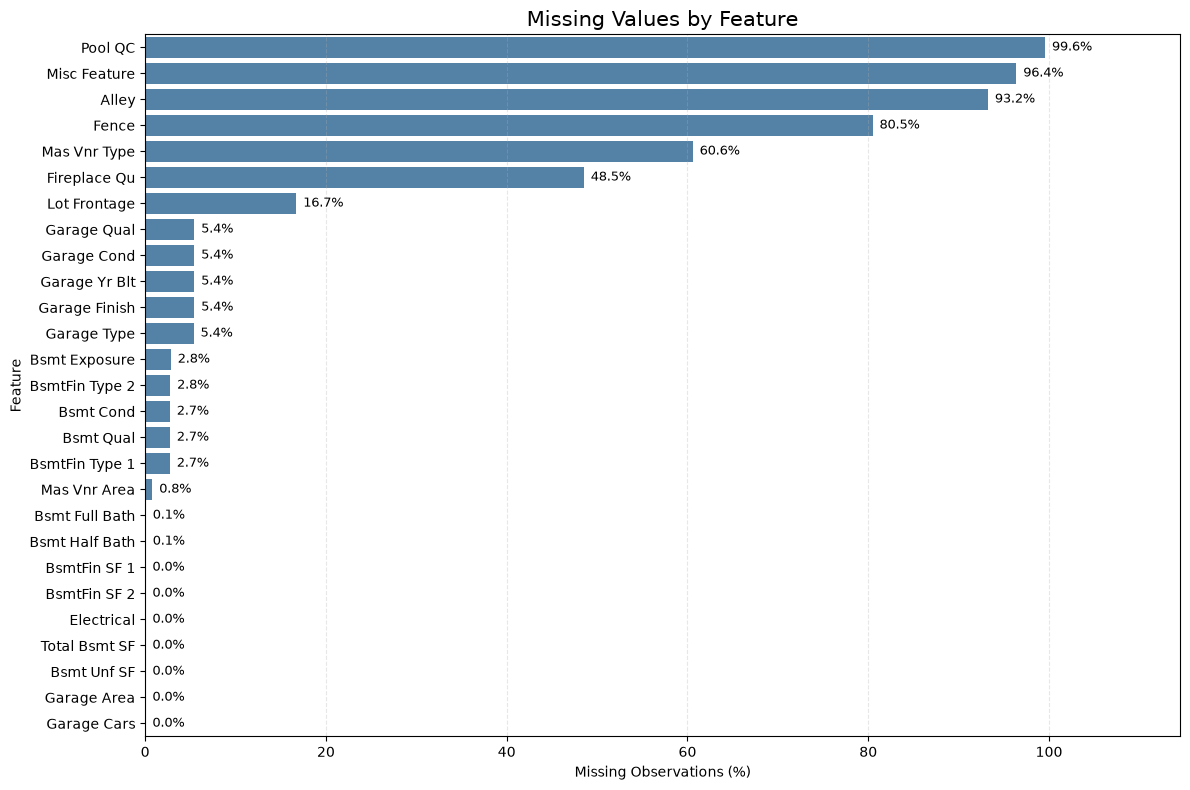

In [25]:

# A5.2 — Missing Values by Feature

plt.figure(figsize=(12, 8))

ax = sns.barplot(
    data=missing_summary.reset_index(),
    x="Missing Percentage",
    y="index",
    color="steelblue"
)

for bar in ax.patches:
    width = bar.get_width()
    ax.annotate(
        f"{width:.1f}%",
        (width, bar.get_y() + bar.get_height() / 2),
        xytext=(5, 0),
        textcoords="offset points",
        ha="left",
        va="center",
        fontsize=9
    )

plt.title("Missing Values by Feature", fontsize=15)
plt.xlabel("Missing Observations (%)")
plt.ylabel("Feature")
plt.xlim(0, max(5, missing_summary["Missing Percentage"].max() * 1.15))
plt.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()


In [26]:

# A5.3 — Features where NA means absence

absence_features = {
    "Alley": "No alley access",
    "Bsmt Qual": "No basement",
    "Bsmt Cond": "No basement",
    "Bsmt Exposure": "No basement",
    "BsmtFin Type 1": "No basement",
    "BsmtFin Type 2": "No basement",
    "Fireplace Qu": "No fireplace",
    "Garage Type": "No garage",
    "Garage Finish": "No garage",
    "Garage Qual": "No garage",
    "Garage Cond": "No garage",
    "Pool QC": "No pool",
    "Fence": "No fence",
    "Misc Feature": "No miscellaneous feature"
}

semantic_missing_summary = missing_summary.copy()

semantic_missing_summary["Documented NA Meaning"] = [
    absence_features.get(col, "Not specified as absence")
    for col in semantic_missing_summary.index
]

display(semantic_missing_summary.round(2))


,Missing Count,Missing Percentage,Documented NA Meaning
Pool QC,2917,99.56,No pool
Misc Feature,2824,96.38,No miscellaneous feature
Alley,2732,93.24,No alley access
Fence,2358,80.48,No fence
Mas Vnr Type,1775,60.58,Not specified as absence
Fireplace Qu,1422,48.53,No fireplace
Lot Frontage,490,16.72,Not specified as absence
Garage Qual,159,5.43,No garage
Garage Cond,159,5.43,No garage
Garage Yr Blt,159,5.43,Not specified as absence


In [27]:

# A5.4 — Garage consistency

garage_check = pd.DataFrame({
    "Garage Type Missing": df["Garage Type"].isna(),
    "Garage Cars": df["Garage Cars"],
    "Garage Area": df["Garage Area"]
})

garage_consistency = pd.crosstab(
    garage_check["Garage Type Missing"],
    garage_check["Garage Cars"].fillna(-1) == 0,
    rownames=["Garage Type is NaN"],
    colnames=["Garage Cars equals 0"]
)

display(garage_consistency)

# Inspect potentially inconsistent records
garage_inconsistencies = df.loc[
    df["Garage Type"].isna()
    & (
        (df["Garage Cars"].fillna(0) > 0)
        | (df["Garage Area"].fillna(0) > 0)
    ),
    ["Garage Type", "Garage Cars", "Garage Area"]
]

print("Potential garage inconsistencies:", len(garage_inconsistencies))
display(garage_inconsistencies.head(10))


Garage Cars equals 0,False,True
Garage Type is NaN,,
False,2773,0
True,0,157


Potential garage inconsistencies: 0


,Garage Type,Garage Cars,Garage Area


In [28]:

# A5.5 — Missingness categories

documented_absence_columns = [
    col for col in missing_summary.index
    if col in absence_features
]

other_missing_columns = [
    col for col in missing_summary.index
    if col not in absence_features
]

print(
    "Columns with documented absence semantics:",
    len(documented_absence_columns)
)
print(documented_absence_columns)

print(
    "\nOther columns with missing values:",
    len(other_missing_columns)
)
print(other_missing_columns)


Columns with documented absence semantics: 14
['Pool QC', 'Misc Feature', 'Alley', 'Fence', 'Fireplace Qu', 'Garage Qual', 'Garage Cond', 'Garage Finish', 'Garage Type', 'Bsmt Exposure', 'BsmtFin Type 2', 'Bsmt Cond', 'Bsmt Qual', 'BsmtFin Type 1']

Other columns with missing values: 13
['Mas Vnr Type', 'Lot Frontage', 'Garage Yr Blt', 'Mas Vnr Area', 'Bsmt Full Bath', 'Bsmt Half Bath', 'BsmtFin SF 1', 'BsmtFin SF 2', 'Electrical', 'Total Bsmt SF', 'Bsmt Unf SF', 'Garage Area', 'Garage Cars']


### Interpretation — Missing Values

The missing-value analysis reveals that several features contain incomplete observations. However, missing entries do not always represent unknown information.

According to the Ames Housing data dictionary, `NA` has a specific semantic meaning for certain features. For example, it may indicate the absence of a garage, basement, fireplace, pool, fence, or alley access.

Consequently, treating all missing values identically would risk losing meaningful information about the properties. Features with documented absence semantics should be investigated separately from features where values are genuinely unknown.

No missing values were imputed or removed during this exploratory analysis. Appropriate handling strategies should be considered in the preprocessing stage, taking into account the meaning of each feature.

In [29]:

# A6.1 — IQR Outlier Detection

outlier_features = [
    "Lot Area",
    "Gr Liv Area",
    "Total Bsmt SF",
    "Garage Area",
    "SalePrice"
]

outlier_results = []

for col in outlier_features:
    values = df[col].dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_mask = (
        (values < lower_bound)
        | (values > upper_bound)
    )

    outlier_results.append({
        "Feature": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": outlier_mask.sum(),
        "Outlier Percentage": (
            outlier_mask.mean() * 100
        )
    })

outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary.round(2))


,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,Lot Area,7440.25,11555.25,4115.00,1267.75,17727.75,127,4.33
1,Gr Liv Area,1126.00,1742.75,616.75,200.88,2667.88,75,2.56
2,Total Bsmt SF,793.00,1302.00,509.00,29.50,2065.50,123,4.20
3,Garage Area,320.00,576.00,256.00,-64.00,960.00,42,1.43
4,SalePrice,129500.00,213500.00,84000.00,3500.00,339500.00,137,4.68


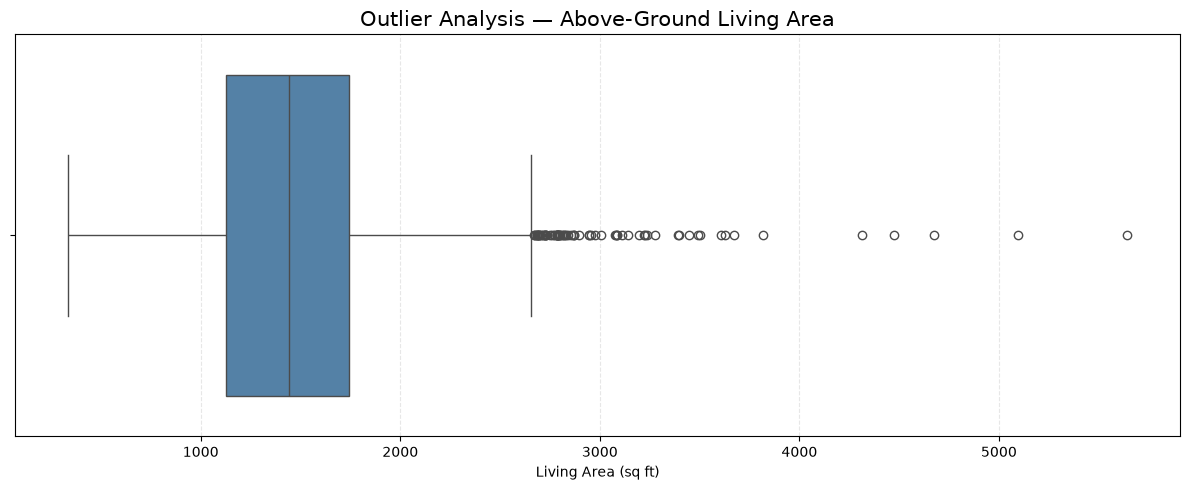

In [30]:

# A6.2 — Living Area Boxplot

plt.figure(figsize=(12, 5))

sns.boxplot(
    data=df,
    x="Gr Liv Area",
    color="steelblue"
)

plt.title(
    "Outlier Analysis — Above-Ground Living Area",
    fontsize=15
)
plt.xlabel("Living Area (sq ft)")

plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()


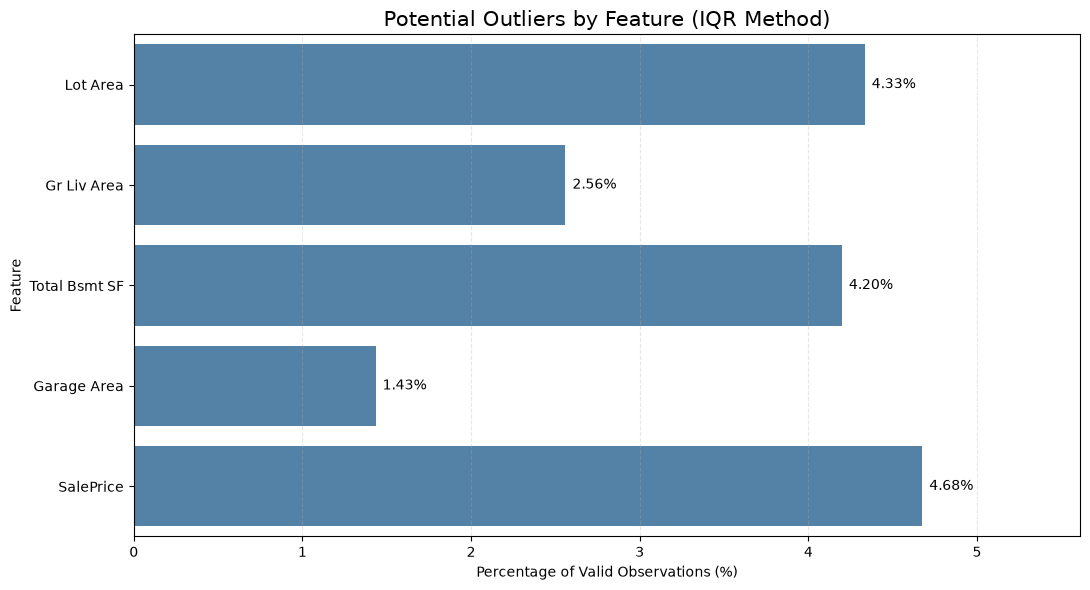

In [31]:

# A6.3 — Outlier Percentage by Feature

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=outlier_summary,
    x="Outlier Percentage",
    y="Feature",
    color="steelblue"
)

for bar in ax.patches:
    width = bar.get_width()

    ax.annotate(
        f"{width:.2f}%",
        (width, bar.get_y() + bar.get_height() / 2),
        xytext=(5, 0),
        textcoords="offset points",
        ha="left",
        va="center"
    )

plt.title(
    "Potential Outliers by Feature (IQR Method)",
    fontsize=15
)
plt.xlabel("Percentage of Valid Observations (%)")
plt.ylabel("Feature")

plt.xlim(
    0,
    max(1, outlier_summary["Outlier Percentage"].max() * 1.2)
)

plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()


In [32]:

# A6.4 — Inspect Properties with Largest Living Areas

largest_properties = df.nlargest(
    10,
    "Gr Liv Area"
)[
    [
        "PID",
        "Neighborhood",
        "Gr Liv Area",
        "Lot Area",
        "Overall Qual",
        "SalePrice"
    ]
]

display(largest_properties)


,PID,Neighborhood,Gr Liv Area,Lot Area,Overall Qual,SalePrice
1498,908154235,Edwards,5642,63887,10,160000
2180,908154195,Edwards,5095,39290,10,183850
2181,908154205,Edwards,4676,40094,10,184750
1760,528320050,NoRidge,4476,15623,10,745000
1767,528351010,NoRidge,4316,21535,10,755000
1497,908154080,Edwards,3820,47007,5,284700
2737,905427030,Edwards,3672,19800,6,415000
2445,528320060,NoRidge,3627,35760,10,625000
2666,902400110,OldTown,3608,22950,10,475000
2450,528360050,NoRidge,3500,17242,9,584500


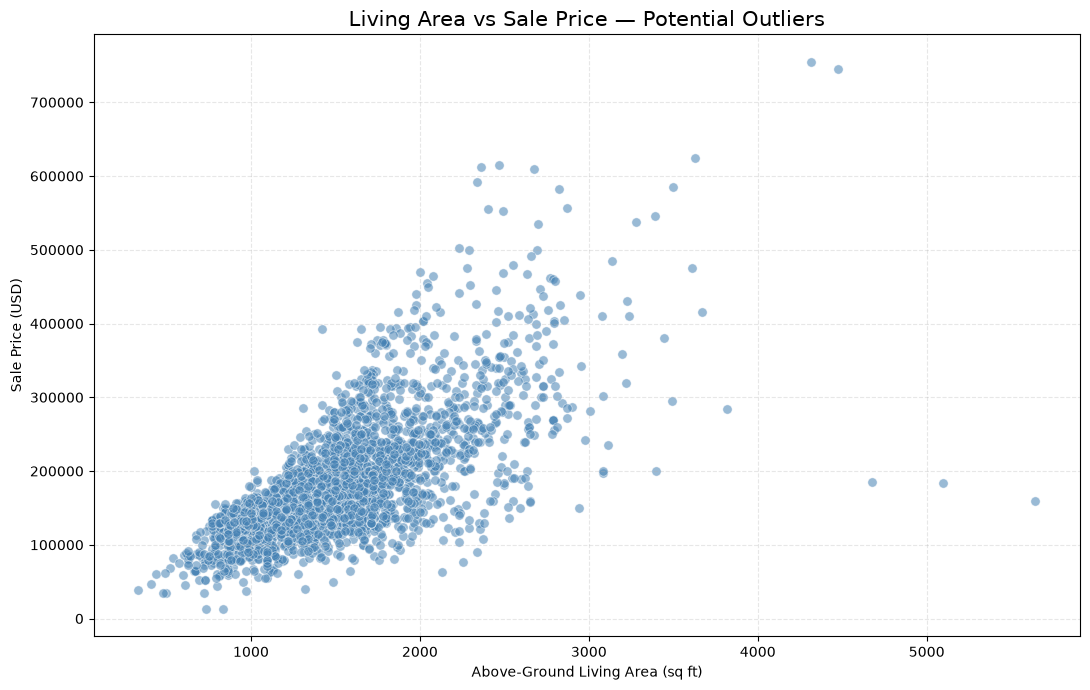

In [33]:

# A6.5 — Living Area vs SalePrice

plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=df,
    x="Gr Liv Area",
    y="SalePrice",
    alpha=0.55,
    color="steelblue",
    s=45
)

plt.title(
    "Living Area vs Sale Price — Potential Outliers",
    fontsize=15
)
plt.xlabel("Above-Ground Living Area (sq ft)")
plt.ylabel("Sale Price (USD)")

plt.grid(linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()


### Interpretation — Outlier Analysis

Potential outliers were investigated using the Interquartile Range (IQR) method for selected continuous variables, including lot area, above-ground living area, basement area, garage area, and sale price.

Observations outside the interval defined by 1.5 times the IQR below the first quartile or above the third quartile were flagged as potential outliers.

Boxplots and scatterplots were used to examine the distribution of these observations and provide additional context. In particular, the relationship between above-ground living area and sale price was inspected to identify properties with unusual combinations of size and price.

It is important to distinguish statistical outliers from data errors. Extremely large or expensive properties may represent legitimate real estate transactions.

Therefore, no observations were removed or modified during this analysis. Any future treatment of outliers should be justified by the dataset's characteristics and the requirements of the predictive modeling task.